# Strategy Reality Check

**A tool that tests an investing strategy against the S&P 500 and estimates, with a model trained on simulated markets, whether its past success is likely to be luck.**

*Prototype, not financial advice.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SabaSad/veritas-ai-hackathon/blob/main/notebooks/Strategy_Reality_Check.ipynb)

**How to use this notebook:** run the cells from top to bottom. Each section explains in plain language what it does, runs one script from the `src/` folder, and shows the result. Everything printed below is computed by the code when you run it.

## 0. Setup

If you are on Google Colab, this cell downloads the project and installs what it needs. On your own computer it does nothing except make sure we are in the project's main folder. It also creates the output folders that Git does not store.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("veritas-ai-hackathon"):                     # download the project only once
        !git clone https://github.com/SabaSad/veritas-ai-hackathon.git
    os.chdir("veritas-ai-hackathon")                                  # all later cells run from the project root
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                                         # locally: go from notebooks/ up to the project root

for folder in ("data/processed", "results", "figures"):    # folders our scripts write into
    os.makedirs(folder, exist_ok=True)

assert os.path.isdir("src"), "Run this notebook from the project (or open it from the notebooks/ folder)."
print("Working folder:", os.getcwd())

Working folder: <project root>


## 1. Download real prices

We need daily prices for **SPY** (a fund that tracks the S&P 500, i.e. "the market") and the **9 original sector ETFs** (funds that each hold one part of the market, such as energy, technology or health care). Prices are *adjusted*, which means dividends and splits are included, so a price change is the real return an investor got.

The script prints the first available date of each fund and warns about any missing data.

In [2]:
!"{sys.executable}" src/load_prices.py

First available date per ticker:
  SPY: 2000-01-03
  XLB: 2000-01-03
  XLE: 2000-01-03
  XLF: 2000-01-03
  XLI: 2000-01-03
  XLK: 2000-01-03
  XLP: 2000-01-03
  XLU: 2000-01-03
  XLV: 2000-01-03
  XLY: 2000-01-03

Tickers with missing data (after their first date):
  none

ETFs starting after 2000: none (all have data from the first trading days of 2000)


## 2. Backtest three simple strategies against SPY

A **backtest** replays a strategy on past data. Ours are:

* **A. Last year's winners:** each December, buy the 3 sectors that did best that year.
* **B. 12-month momentum:** each month, buy the 3 sectors that did best over the last 12 months.
* **C. Equal weight:** hold all 9 sectors equally.

**No peeking:** a decision made at the end of a month can only earn money in the *next* month. We never use information from the future.

The table shows each strategy's total return, yearly return, volatility (how bumpy the ride was), and the *excess return*, which is how much it beat (or lost to) SPY per year. It is shown for the whole period and for two halves, so you can see whether a strategy that looked good in the first half kept it up.

In [3]:
!"{sys.executable}" src/backtest.py

   Period              Strategy   Total Annualised Volatility Excess vs SPY (ann.)
2000-2026 A Last year's winners  769.5%       9.1%      15.8%                -0.8%
2000-2026        B 12m momentum 1060.4%      10.0%      14.4%                 1.2%
2000-2026        C Equal weight  952.8%       9.2%      14.7%                 0.8%
2000-2026        SPY buy & hold  764.8%       8.4%      15.1%                  NaN
2000-2020 A Last year's winners  323.2%       7.9%      15.7%                -0.6%
2000-2020        B 12m momentum  346.8%       7.8%      14.4%                 0.6%
2000-2020        C Equal weight  386.2%       7.9%      14.9%                 1.0%
2000-2020        SPY buy & hold  297.0%       6.8%      15.1%                  NaN
2021-2026 A Last year's winners  105.4%      12.9%      16.1%                -1.1%
2021-2026        B 12m momentum  159.7%      17.5%      14.5%                 3.4%
2021-2026        C Equal weight  116.5%      13.9%      13.7%                -0.1%
2021

## 3. Simulated markets (takes about 5 minutes)

Real history is only one story. To see how often a strategy looks good *by pure luck*, we build many **simulated markets** from real months: each market is made by drawing 180 real months at random, with replacement (a "bootstrap"). The same drawn months are used for all 10 funds, so their relationships stay realistic.

Because the months are mixed up, **no strategy can have real skill in these markets**. Any "winner" we find there is lucky by construction.

In each market we test 20 momentum strategies and imitate a person who tried **K** of them and kept the one with the best result on the first 120 months (the "past"). Then we record how that winner did on the last 60 months (the "new data"). The more strategies you try (bigger K), the better the best one looks in the past, but luck does not carry over.

The table printed at the end shows, for each K, the winners' average past excess and average new-data excess.

In [4]:
!"{sys.executable}" src/simulate.py

   past_excess new_excess
K                        
1        0.63%      0.89%
3        2.68%      0.87%
5        3.23%      0.73%
10       4.16%      0.74%
20       5.06%      0.39%


## 4. Train a model and compare it with two simple baselines

**Goal:** from what you can see in the past (the winner's past excess return, its tracking error, how many strategies were tried, ...), predict how the winner will do on new data.

* **Baseline 1, "trust the backtest":** assume the past result repeats.
* **Baseline 2, "always the average":** always predict the typical new-data result.
* **Models:** a linear regression and a gradient boosting model.

We split the simulated markets 80% / 20% **by whole market**, so the model is never tested on a market it has partly seen. All scores below are on the 20% test markets only.

The chart compares predicted and actual new-data excess return for five groups of winners, from the lowest to the highest past excess.

Markets: train 1600, test 400, in both sets: 0  ->  OK

=== ALL TEST ROWS ===
                                   MAE    RMSE   AUROC   Brier
Baseline 1: trust the backtest  0.0445  0.0596  0.4777  0.4400
Baseline 2: always the average  0.0339  0.0451  0.5000  0.4060
Linear regression               0.0338  0.0449  0.5841     NaN
Gradient boosting               0.0349  0.0463  0.5091  0.2564
Reference Brier if we always predict P(beats SPY) = 0.57: 0.2417

=== K = 1 (400 test rows) ===
                                   MAE    RMSE   AUROC   Brier
Baseline 1: trust the backtest  0.0374  0.0490  0.5112  0.4725
Baseline 2: always the average  0.0291  0.0390  0.5000  0.3850
Linear regression               0.0290  0.0389  0.5698     NaN
Gradient boosting               0.0299  0.0402  0.5090  0.2497

=== K = 3 (400 test rows) ===
                                   MAE    RMSE   AUROC   Brier
Baseline 1: trust the backtest  0.0376  0.0493  0.5248  0.4225
Baseline 2: always the average  0.0311 

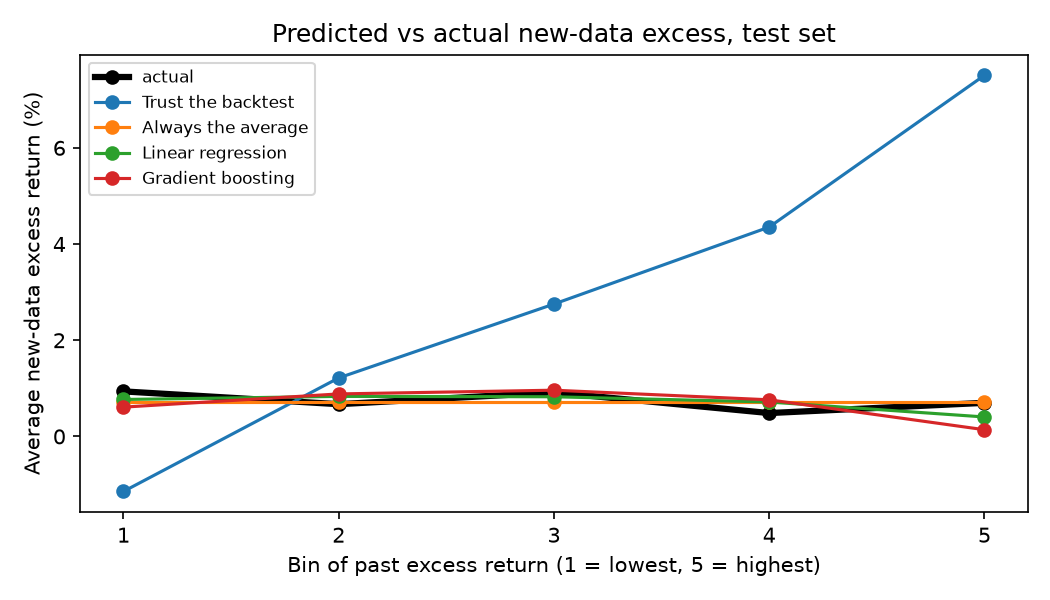

In [5]:
!"{sys.executable}" src/train_model.py
from IPython.display import Image, display
display(Image("figures/calibration.png"))

## 5. One real test: past 2011-2020, new 2021-2025

Now the real world. We run the same 20 strategies on real months in their real order. The models are **trained only on the simulated markets**, never on real data. Then we check what they predict for the real winners and what actually happened.

The 20-strategy table shows each strategy's excess return in the past and afterwards. The chart plots them: a point on the dashed line would mean "the past result repeated exactly".

Months: Jan 2011 to Dec 2025, count = 180
  past: Jan 2011 to Dec 2020 (120 months)
  new : Jan 2021 to Dec 2025 (60 months)

All 20 strategies (excess return vs SPY, % per year):
 L  top_k  past_excess  new_excess
 1      1        -4.92        2.24
 1      2        -4.88        0.68
 1      3        -3.93        1.20
 1      4        -1.65       -1.57
 1      5        -1.95       -2.92
 3      1        -4.55       -2.46
 3      2        -3.50        1.54
 3      3        -0.87       -1.77
 3      4        -0.91       -3.65
 3      5        -1.81       -3.96
 6      1        -2.76       -0.07
 6      2        -1.70       -4.25
 6      3        -1.78       -4.89
 6      4        -1.52       -2.13
 6      5        -1.62       -2.31
12      1        -5.26        8.11
12      2        -3.68        1.28
12      3        -2.68       -0.19
12      4        -1.98       -0.75
12      5        -1.34       -0.63

Spearman rank correlation, past vs new excess across the 20 strategies: -0.65

K=20 

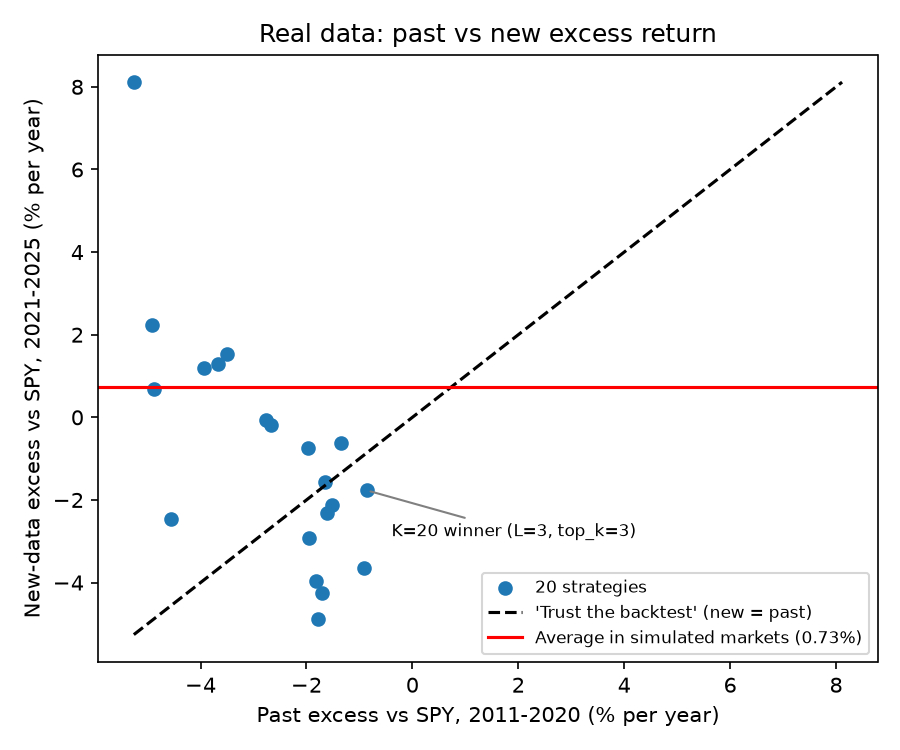

In [6]:
!"{sys.executable}" src/real_test.py
display(Image("figures/real_test.png"))

## 6. Rolling real windows

One window could be a fluke, so we repeat the real test in every possible 15-year window (10 years past, 5 years new), moving by one year each time. This is **descriptive only**: no model is trained here.

The table follows the winner among all 20 strategies in each window. The chart plots its past excess return against what it earned afterwards, one dot per window.

Real months: Feb 2000 to Dec 2025 (311 months)
11 windows of 180 months:
  window  1: Jan 2001 - Dec 2015 (past to Dec 2010, new from Jan 2011)
  window  2: Jan 2002 - Dec 2016 (past to Dec 2011, new from Jan 2012)
  window  3: Jan 2003 - Dec 2017 (past to Dec 2012, new from Jan 2013)
  window  4: Jan 2004 - Dec 2018 (past to Dec 2013, new from Jan 2014)
  window  5: Jan 2005 - Dec 2019 (past to Dec 2014, new from Jan 2015)
  window  6: Jan 2006 - Dec 2020 (past to Dec 2015, new from Jan 2016)
  window  7: Jan 2007 - Dec 2021 (past to Dec 2016, new from Jan 2017)
  window  8: Jan 2008 - Dec 2022 (past to Dec 2017, new from Jan 2018)
  window  9: Jan 2009 - Dec 2023 (past to Dec 2018, new from Jan 2019)
  window 10: Jan 2010 - Dec 2024 (past to Dec 2019, new from Jan 2020)
  window 11: Jan 2011 - Dec 2025 (past to Dec 2020, new from Jan 2021)

K=20 winner by window (excess return vs SPY, % per year):
 window   start     end  winner_L  winner_top_k  past   new  spearman
      1 2001-01 2

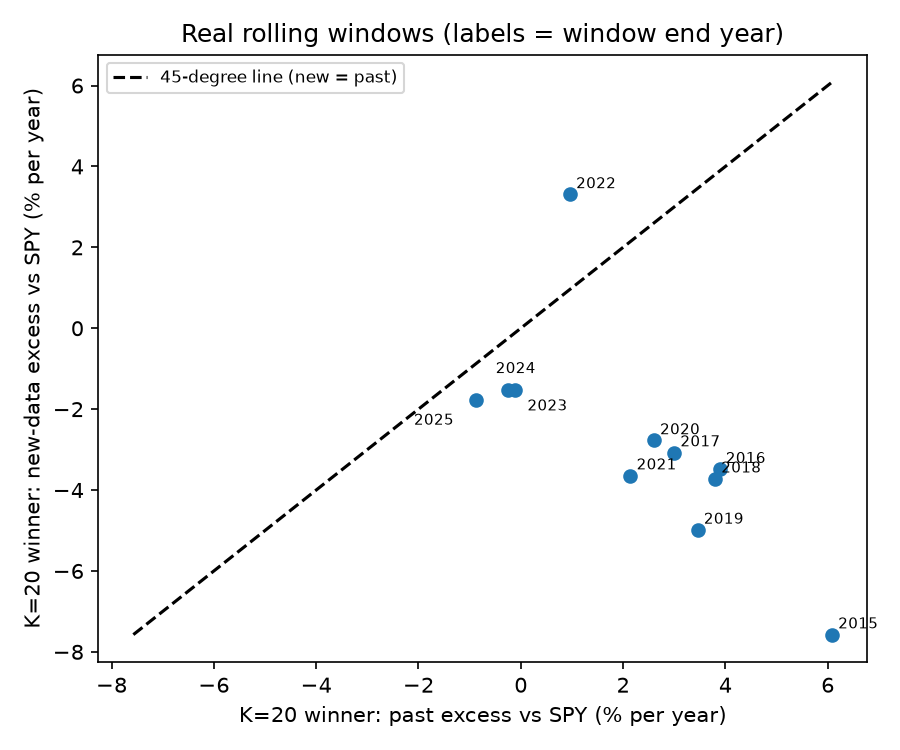

In [7]:
!"{sys.executable}" src/rolling_real.py
display(Image("figures/rolling_real.png"))

## Where it fails (honest limitations)

* **One real unseen window.** Only the last window (past 2011-2020, new 2021-2025) is fully unseen by the simulation. Everything else is illustrative.
* **Overlapping windows.** The rolling windows share most of their months, so they are not independent observations and are not a statistical test.
* **The simulation reshuffles 2000-2020 months.** Windows whose new years end in 2020 or earlier use months that the simulation also drew from.
* **The models barely beat "always the average".** Compare the model rows with the baseline rows in the table above. The gap is small and not the same for every K.
* **Regime shift.** Markets change over time. A bootstrap mixes all periods together and cannot capture a change in how markets behave.
* **No trading costs.** Real trading has fees and taxes, which would make every strategy look worse.
* **Sector ETFs only.** We only tried simple momentum rules on 9 US sector funds, not other assets, countries or kinds of strategies.

## 7. Try it yourself: the demo

This last cell starts the **Strategy Reality Check** demo. Pick a historical window and a strategy, say how many strategies you tried first, and the demo shows how it did, what winners like yours did afterwards in simulated no-skill markets, and the model's estimate. You can then reveal what really happened.

On Colab the cell creates a public link. **The link only works while this notebook is running.**

In [8]:
sys.path.insert(0, "src")        # so we can import app.py from the src folder
import app

if IN_COLAB:
    app.demo.launch(share=True)  # public link, valid while the notebook runs
else:
    app.demo.launch()            # local only

* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.
